# Maintenance prédictive des moteurs d'avion : prévoir la panne avant qu'elle n'arrive

**Question** : à partir des capteurs d'un turboréacteur, peut-on prévoir **combien de vols il lui reste avant la panne**, et déclencher une alerte de maintenance au bon moment ?

**Pourquoi c'est important** : un accident d'avion n'a presque jamais une cause unique, mais la défaillance d'un moteur en vol fait partie des événements que l'aéronautique cherche à éviter à tout prix. Les compagnies (Air France Industries, Safran, Rolls-Royce avec son programme *Engine Health Monitoring*) surveillent donc en continu leurs moteurs pour intervenir **avant** la panne, ni trop tôt (on immobilise un avion pour rien), ni trop tard (risque en vol).

**Ce que montre ce notebook**
1. Lire des séries temporelles de capteurs et repérer la dégradation d'un moteur.
2. Construire des variables **sans fuite de données** (on ne regarde que le passé).
3. Comparer trois modèles (Ridge, forêt aléatoire, XGBoost) avec une validation croisée **par moteur**.
4. Évaluer sur le jeu de test officiel de la NASA, avec le **score asymétrique** du challenge PHM 2008 (prévoir trop tard est plus grave que prévoir trop tôt).
5. Transformer la prévision en **décision** : quand envoyer le moteur en inspection, en minimisant un coût métier.
6. Expliquer les prévisions (valeurs de Shapley) et vérifier que le modèle s'appuie sur une physique cohérente.

**Données** : NASA C-MAPSS (*Commercial Modular Aero-Propulsion System Simulation*), Saxena et al., 2008. 100 moteurs simulés tournent jusqu'à la panne (entraînement) ; 100 autres sont coupés avant la panne et il faut prévoir leur durée de vie restante (test).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             average_precision_score, precision_score, recall_score)
import xgboost as xgb

from src import data as D, features as F, models as M, evaluation as E

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
RES = Path("../resultats"); RES.mkdir(exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

SOUS_JEU = "FD001"      # une condition de vol, un mode de panne (compresseur HP)
HORIZON = 30            # alerte si la panne est prévue dans les 30 prochains cycles

## 1. Les données : 100 moteurs qui tournent jusqu'à la panne

In [2]:
train, test = D.charger(SOUS_JEU)
print(f"Entraînement : {train.moteur.nunique()} moteurs, {len(train):,} cycles")
print(f"Test         : {test.moteur.nunique()} moteurs, {len(test):,} cycles")
train.head()

Entraînement : 100 moteurs, 20,631 cycles
Test         : 100 moteurs, 13,096 cycles


,moteur,cycle,reglage1,reglage2,reglage3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.001,-0.000,100.000,518.670,641.820,"1,589.700","1,400.600",14.620,...,"2,388.020","8,138.620",8.419,0.030,392,2388,100.000,39.060,23.419,191
1,1,2,0.002,-0.000,100.000,518.670,642.150,"1,591.820","1,403.140",14.620,...,"2,388.070","8,131.490",8.432,0.030,392,2388,100.000,39.000,23.424,190
2,1,3,-0.004,0.000,100.000,518.670,642.350,"1,587.990","1,404.200",14.620,...,"2,388.030","8,133.230",8.418,0.030,390,2388,100.000,38.950,23.344,189
3,1,4,0.001,0.000,100.000,518.670,642.350,"1,582.790","1,401.870",14.620,...,"2,388.080","8,133.830",8.368,0.030,392,2388,100.000,38.880,23.374,188
4,1,5,-0.002,-0.000,100.000,518.670,642.370,"1,582.850","1,406.220",14.620,...,"2,388.040","8,133.800",8.429,0.030,393,2388,100.000,38.900,23.404,187


Un **cycle** correspond à un vol. Chaque ligne donne les 3 réglages de vol et 21 mesures de capteurs (températures, pressions, vitesses de rotation). La colonne `RUL` (*Remaining Useful Life*) est la cible : le nombre de cycles restants avant la panne.

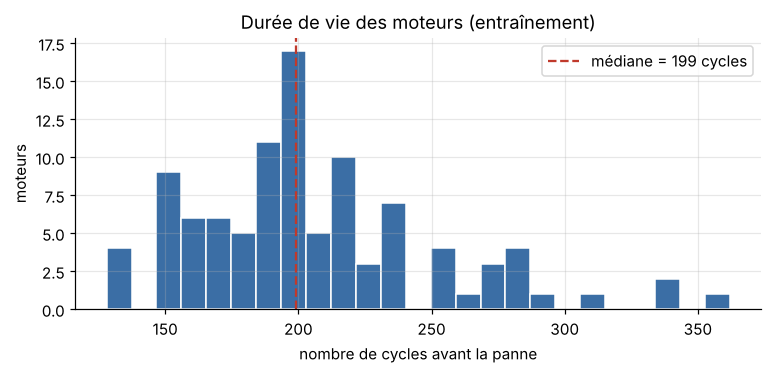

count   100.000
mean    206.000
std      46.000
min     128.000
25%     177.000
50%     199.000
75%     229.000
max     362.000
Name: cycle, dtype: float64


In [3]:
duree = train.groupby("moteur")["cycle"].max()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(duree, bins=25, color="#3b6ea5", edgecolor="white")
ax.axvline(duree.median(), color="#c0392b", ls="--", label=f"médiane = {duree.median():.0f} cycles")
ax.set(title="Durée de vie des moteurs (entraînement)", xlabel="nombre de cycles avant la panne", ylabel="moteurs")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "01_duree_de_vie.png", bbox_inches="tight"); plt.show()
print(duree.describe().round(0))

Les durées de vie vont du simple au triple : **on ne peut pas se contenter d'un calendrier fixe de maintenance**. Un moteur qui casse à 130 cycles et un autre à 360 cycles demandent des décisions différentes, d'où l'intérêt de regarder les capteurs.

## 2. Quels capteurs voient la dégradation ?

Capteurs constants (retirés) : ['s1', 's5', 's10', 's16', 's18', 's19']
Capteurs gardés : 15


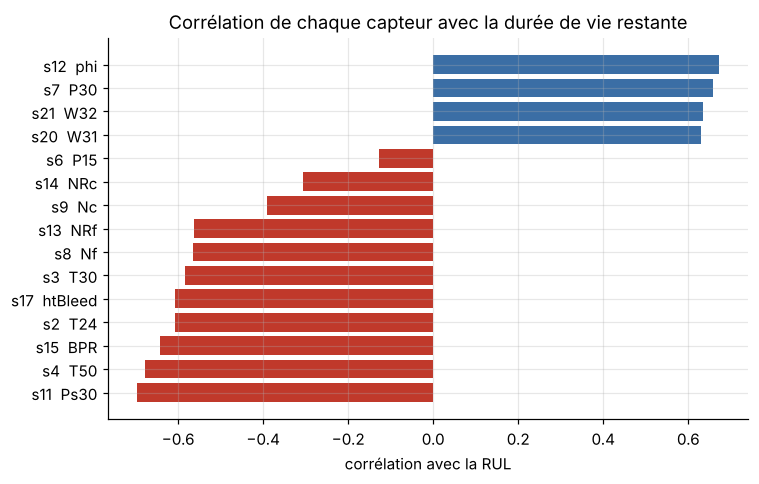

In [4]:
capteurs = D.capteurs_utiles(train)
constants = sorted(set(D.CAPTEURS) - set(capteurs), key=lambda c: int(c[1:]))
print("Capteurs constants (retirés) :", constants)
print("Capteurs gardés :", len(capteurs))

corr = train[capteurs + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
couleurs = np.where(corr < 0, "#c0392b", "#3b6ea5")
ax.barh([f"{c}  {D.CAPTEURS[c].split(' - ')[0]}" for c in corr.index], corr, color=couleurs)
ax.set(title="Corrélation de chaque capteur avec la durée de vie restante", xlabel="corrélation avec la RUL")
plt.tight_layout(); plt.savefig(FIG / "02_correlation_capteurs.png", bbox_inches="tight"); plt.show()

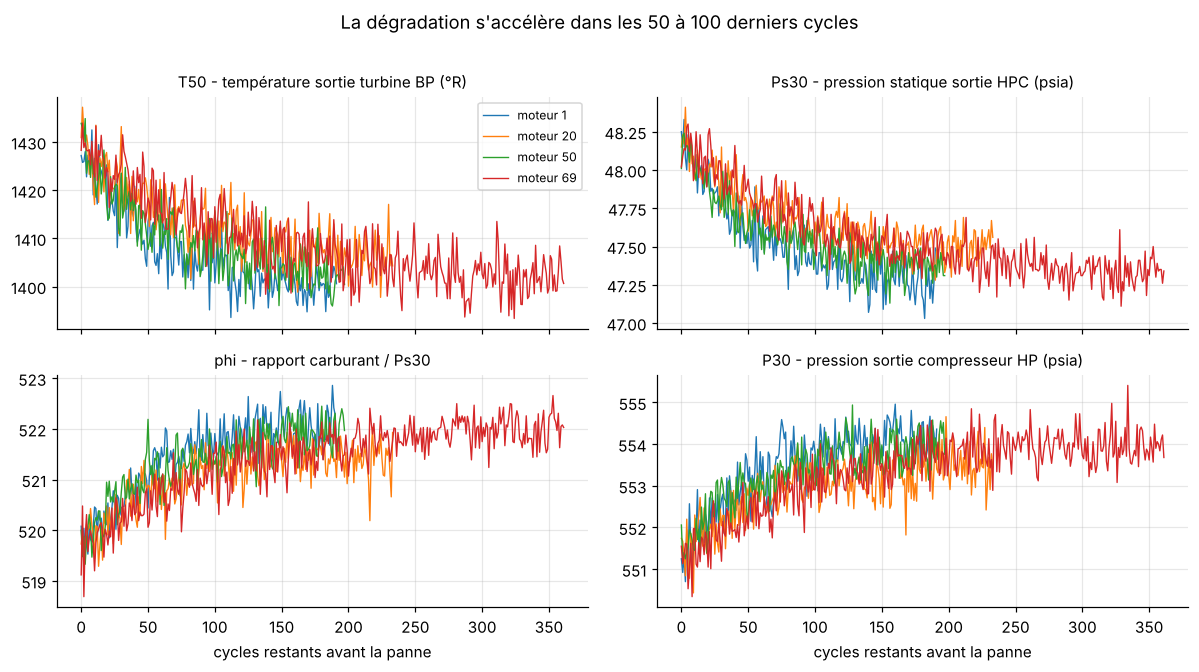

In [5]:
exemples = [1, 20, 50, 69]
a_tracer = ["s4", "s11", "s12", "s7"]
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, c in zip(axes.ravel(), a_tracer):
    for m in exemples:
        d = train[train.moteur == m]
        ax.plot(d["RUL"], d[c], lw=.9, label=f"moteur {m}")
    ax.set_title(D.CAPTEURS[c], fontsize=10)
    ax.invert_xaxis()
axes[1, 0].set_xlabel("cycles restants avant la panne"); axes[1, 1].set_xlabel("cycles restants avant la panne")
axes[0, 0].legend(fontsize=8)
fig.suptitle("La dégradation s'accélère dans les 50 à 100 derniers cycles", y=1.01)
plt.tight_layout(); plt.savefig(FIG / "03_trajectoires_capteurs.png", bbox_inches="tight"); plt.show()

**Lecture** : en début de vie, les capteurs sont plats (le moteur est sain, seul le bruit de mesure bouge). Puis la panne du compresseur haute pression s'installe : la température en sortie de turbine (T50) monte, la pression statique (Ps30) augmente, le rapport carburant/pression (phi) baisse. Le moteur consomme plus pour fournir la même poussée.

**Conséquence pour la modélisation** : tant que le moteur est sain, rien dans les capteurs ne permet de distinguer 300 cycles restants de 150. On **plafonne donc la cible à 125 cycles** (méthode classique, Heimes 2008) : le modèle apprend « sain » puis un compte à rebours.

## 3. Variables explicatives : ne regarder que le passé

Un mécanicien ne juge pas un moteur sur une seule mesure bruitée, mais sur la **tendance**. Pour chaque capteur et à chaque cycle, on calcule :
- la moyenne glissante sur 5 et 20 cycles (lisse le bruit) ;
- l'écart-type sur 20 cycles (instabilité) ;
- la **pente** sur 20 cycles (vitesse de dégradation) ;
- la dérive par rapport aux 10 premiers cycles du moteur (écart à son état neuf).

Toutes les fenêtres sont **causales** : au cycle *t*, on n'utilise que les cycles 1 à *t*. C'est exactement l'information dont disposerait la compagnie en exploitation.

In [6]:
X_train = F.construire(train, capteurs)
X_test = F.construire(test, capteurs)
COLS = F.colonnes_X(X_train)
y_train = train["RUL"].clip(upper=D.RUL_MAX)
groupes = train["moteur"]
print(f"{len(COLS)} variables pour {len(X_train):,} cycles d'entraînement")

91 variables pour 20,631 cycles d'entraînement


## 4. Comparaison des modèles (validation croisée par moteur)

Piège classique : mélanger les cycles d'un même moteur entre entraînement et validation. Le modèle « reconnaît » alors le moteur et les scores sont trop beaux. On utilise donc une **validation croisée groupée** (`GroupKFold`) : les 100 moteurs sont répartis en 5 paquets, et un moteur n'apparaît jamais des deux côtés.

In [7]:
oof, lignes = {}, []
for nom, modele in M.modeles_regression().items():
    oof[nom] = np.clip(M.predictions_hors_echantillon(modele, X_train[COLS], y_train, groupes), 0, None)
    lignes.append({"modèle": nom, **E.resume_regression(y_train, oof[nom])})
comparaison = pd.DataFrame(lignes).set_index("modèle").drop(columns="Score NASA")
comparaison.to_csv(RES / "comparaison_validation.csv")
comparaison

,RMSE,MAE,R²
modèle,,,
Ridge (linéaire),16.317,13.032,0.847
Forêt aléatoire,10.520,7.062,0.936
XGBoost,9.367,6.353,0.949


La relation entre capteurs et usure n'est pas linéaire (la dégradation s'accélère en fin de vie) : les modèles d'arbres font nettement mieux que la régression Ridge.

## 5. Évaluation finale sur le jeu de test officiel de la NASA

In [8]:
fin_test = test.groupby("moteur")["cycle"].idxmax().values   # dernier cycle observé de chaque moteur
y_test = test.loc[fin_test, "RUL"].clip(upper=D.RUL_MAX).to_numpy()

modeles, pred_test, lignes = {}, {}, []
for nom, modele in M.modeles_regression().items():
    modele.fit(X_train[COLS], y_train)
    modeles[nom] = modele
    pred_test[nom] = np.clip(modele.predict(X_test.loc[fin_test, COLS]), 0, None)
    lignes.append({"modèle": nom, **E.resume_regression(y_test, pred_test[nom])})
resultats = pd.DataFrame(lignes).set_index("modèle")
resultats.to_csv(RES / "resultats_test.csv")
resultats

,RMSE,MAE,R²,Score NASA
modèle,,,,
Ridge (linéaire),16.389,13.323,0.833,415.220
Forêt aléatoire,11.418,8.109,0.919,189.302
XGBoost,11.030,7.784,0.924,178.302


**Comment lire ces chiffres**
- **RMSE** : erreur typique en nombre de cycles (vols). Les articles de référence sur FD001 obtiennent entre 11 et 18 avec des réseaux de neurones profonds (CNN, LSTM) ; un XGBoost bien nourri en variables fait aussi bien.
- **Score NASA** : pénalise exponentiellement les prévisions **trop optimistes** (on annonce 40 cycles restants alors que le moteur casse dans 20). C'est le critère qui compte pour la sécurité.

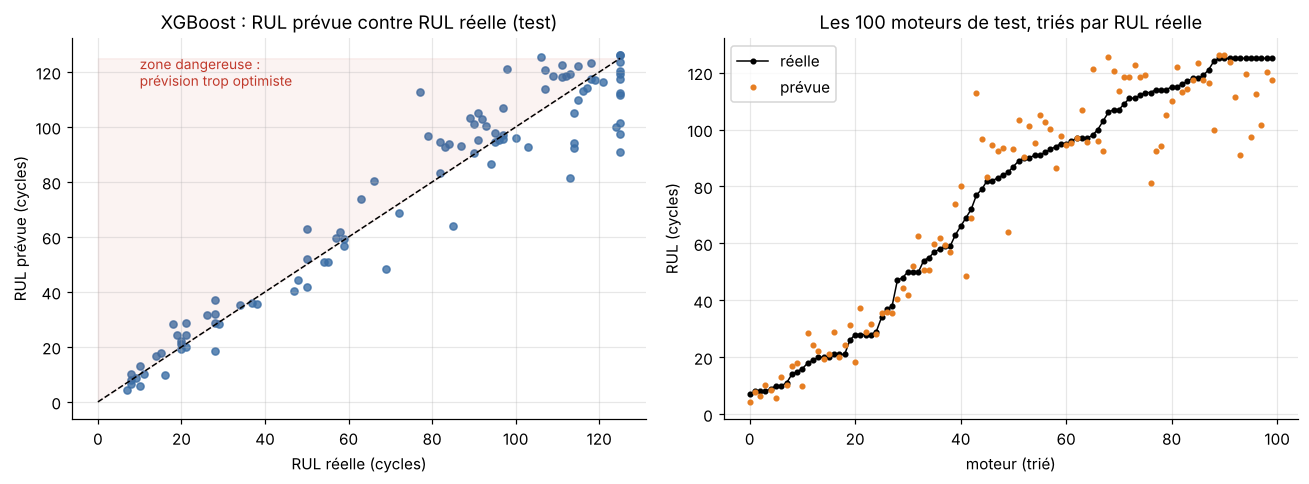

In [9]:
meilleur = resultats["RMSE"].idxmin()
p = pred_test[meilleur]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.scatter(y_test, p, s=22, alpha=.8, color="#3b6ea5")
ax.plot([0, D.RUL_MAX], [0, D.RUL_MAX], "k--", lw=1)
ax.fill_between([0, D.RUL_MAX], [0, D.RUL_MAX], [D.RUL_MAX] * 2, color="#c0392b", alpha=.06)
ax.text(10, 115, "zone dangereuse :\nprévision trop optimiste", color="#c0392b", fontsize=9)
ax.set(title=f"{meilleur} : RUL prévue contre RUL réelle (test)", xlabel="RUL réelle (cycles)", ylabel="RUL prévue (cycles)")
ordre = np.argsort(y_test)
ax = axes[1]
ax.plot(y_test[ordre], "o-", ms=3, color="black", lw=1, label="réelle")
ax.plot(p[ordre], "o", ms=3, color="#e67e22", label="prévue")
ax.set(title="Les 100 moteurs de test, triés par RUL réelle", xlabel="moteur (trié)", ylabel="RUL (cycles)")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_prevision_test.png", bbox_inches="tight"); plt.show()

Point rassurant : **l'erreur diminue quand la panne approche**. Pour un moteur sain (RUL réelle > 100), se tromper de 20 cycles n'a aucune conséquence ; près de la panne, c'est là que la précision compte, et c'est là que le modèle est le plus fiable.

In [10]:
err = p - y_test
tranches = pd.cut(y_test, [0, 30, 60, 90, D.RUL_MAX + 1], labels=["0-30", "31-60", "61-90", "91+"], include_lowest=True)
print(pd.DataFrame({"tranche de RUL réelle": tranches, "erreur absolue": np.abs(err)})
      .groupby("tranche de RUL réelle", observed=True)["erreur absolue"].agg(["count", "mean"]).round(1))

                       count   mean
tranche de RUL réelle              
0-30                      25  3.500
31-60                     14  3.900
61-90                     15 12.600
91+                       46  9.700


## 6. Suivre un moteur vol après vol

En exploitation, la prévision est recalculée après chaque vol. Voici ce que verrait un ingénieur de maintenance pour quelques moteurs du test (la vraie RUL est connue grâce au fichier de la NASA).

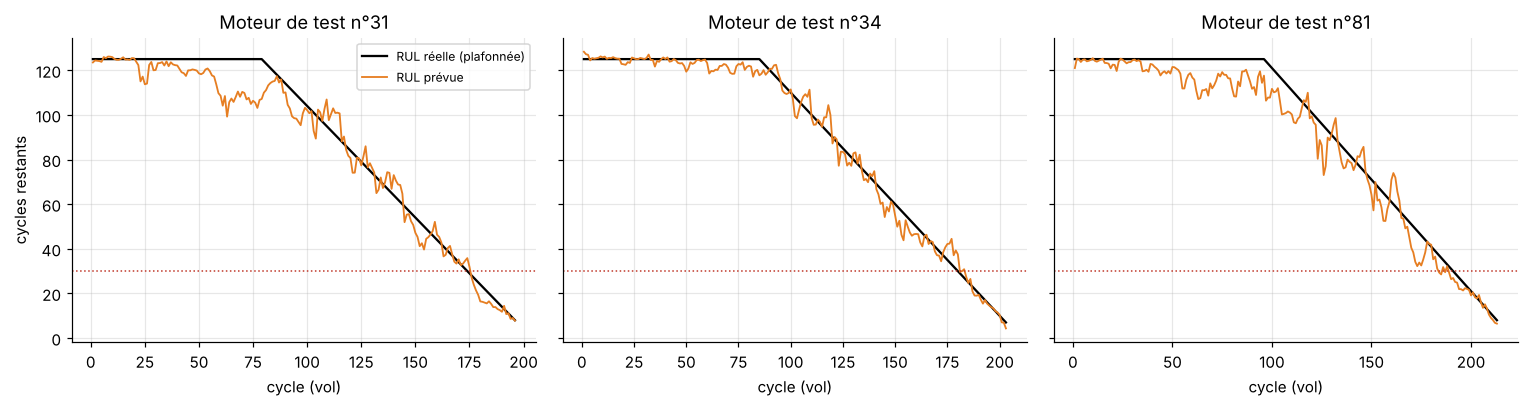

In [11]:
modele = modeles[meilleur]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, m in zip(axes, [31, 34, 81]):
    idx = test.index[test.moteur == m]
    vraie = test.loc[idx, "RUL"].clip(upper=D.RUL_MAX)
    prev = np.clip(modele.predict(X_test.loc[idx, COLS]), 0, None)
    ax.plot(test.loc[idx, "cycle"], vraie, "k-", lw=1.5, label="RUL réelle (plafonnée)")
    ax.plot(test.loc[idx, "cycle"], prev, color="#e67e22", lw=1.2, label="RUL prévue")
    ax.axhline(HORIZON, color="#c0392b", ls=":", lw=1)
    ax.set(title=f"Moteur de test n°{m}", xlabel="cycle (vol)")
axes[0].set_ylabel("cycles restants"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_suivi_moteur.png", bbox_inches="tight"); plt.show()

## 7. De la prévision à la décision : quand envoyer le moteur en inspection ?

Une prévision ne sert à rien sans **règle de décision**. On pose la question métier : *« le moteur va-t-il tomber en panne dans les 30 prochains vols ? »* Si oui, il doit passer en inspection.

Les deux erreurs n'ont pas le même coût :

| Erreur | Conséquence | Coût relatif |
|---|---|---|
| Panne ratée (faux négatif) | arrêt moteur en service, déroutement, avion immobilisé, réparation lourde | **50** |
| Fausse alerte (faux positif) | inspection anticipée de quelques heures | **1** |

On compare deux approches :
- **A. Règle sur la RUL prévue** : alerte si la RUL prévue par XGBoost est inférieure à un seuil *s* ;
- **B. Classifieur direct** : XGBoost estime la probabilité de panne dans les 30 cycles, alerte si elle dépasse un seuil *p*.

Les seuils sont choisis **sur la validation croisée de l'entraînement** (jamais sur le test), en minimisant le coût moyen.

Moteurs du test à moins de 30 cycles de la panne : 25 sur 100


A. alerte si RUL prévue <= 42 cycles  (coût validation 0.059)
B. alerte si probabilité >= 0.05       (coût validation 0.062)
AUC-PR du classifieur (validation) : 0.989


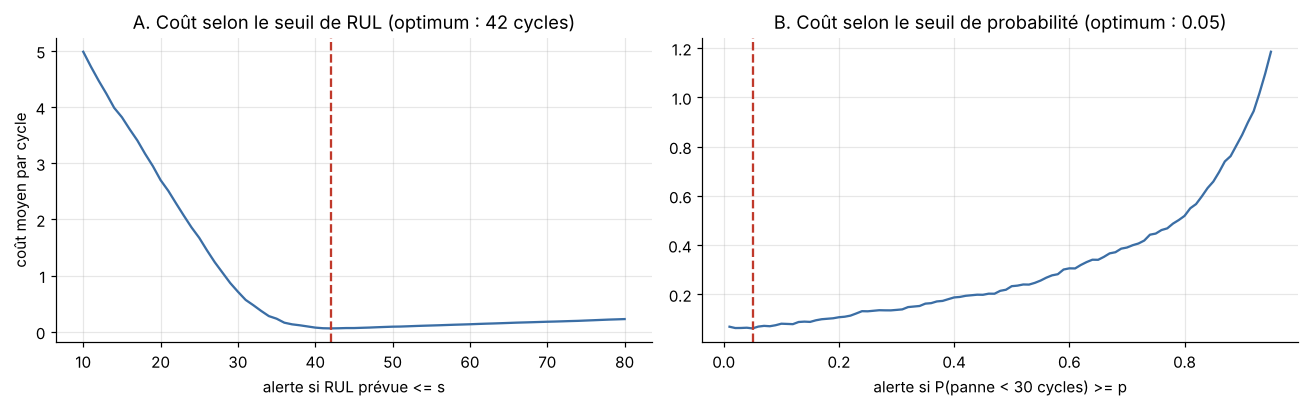

In [12]:
y_alerte_train = (train["RUL"] <= HORIZON).astype(int)
y_alerte_test = (test.loc[fin_test, "RUL"] <= HORIZON).astype(int).to_numpy()
print(f"Moteurs du test à moins de {HORIZON} cycles de la panne : {y_alerte_test.sum()} sur {len(y_alerte_test)}")

# A. règle sur la RUL prévue (prévisions hors échantillon de la section 4)
seuils_rul = np.arange(10, 81)
s_opt, couts_rul = E.meilleur_seuil(y_alerte_train, oof["XGBoost"], seuils_rul, alerte_si_inferieur=True)

# B. classifieur direct
clf = M.modeles_classification(y_alerte_train)["XGBoost"]
proba_oof = M.predictions_hors_echantillon(clf, X_train[COLS], y_alerte_train, groupes, proba=True)
seuils_p = np.round(np.arange(0.01, 0.96, 0.01), 2)
p_opt, couts_p = E.meilleur_seuil(y_alerte_train, proba_oof, seuils_p)
print(f"A. alerte si RUL prévue <= {s_opt:.0f} cycles  (coût validation {couts_rul.min():.3f})")
print(f"B. alerte si probabilité >= {p_opt:.2f}       (coût validation {couts_p.min():.3f})")
print(f"AUC-PR du classifieur (validation) : {average_precision_score(y_alerte_train, proba_oof):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(seuils_rul, couts_rul, color="#3b6ea5"); axes[0].axvline(s_opt, color="#c0392b", ls="--")
axes[0].set(title=f"A. Coût selon le seuil de RUL (optimum : {s_opt:.0f} cycles)", xlabel="alerte si RUL prévue <= s", ylabel="coût moyen par cycle")
axes[1].plot(seuils_p, couts_p, color="#3b6ea5"); axes[1].axvline(p_opt, color="#c0392b", ls="--")
axes[1].set(title=f"B. Coût selon le seuil de probabilité (optimum : {p_opt:.2f})", xlabel="alerte si P(panne < 30 cycles) >= p")
plt.tight_layout(); plt.savefig(FIG / "06_cout_seuil.png", bbox_inches="tight"); plt.show()

Le seuil optimal de la règle A est **supérieur à 30** : comme rater une panne coûte 50 fois plus cher qu'une inspection, on préfère se garder une **marge de sécurité** et alerter un peu avant. C'est le raisonnement réel des équipes de maintenance.

In [13]:
clf.fit(X_train[COLS], y_alerte_train)
proba_test = clf.predict_proba(X_test.loc[fin_test, COLS])[:, 1]
alerte_A = pred_test["XGBoost"] <= s_opt
alerte_B = proba_test >= p_opt
alerte_naif = np.ones_like(y_alerte_test, dtype=bool)  # tout inspecter

def bilan(nom, alerte):
    tn, fp, fn, tp = confusion_matrix(y_alerte_test, alerte, labels=[0, 1]).ravel()
    return {"règle": nom, "pannes détectées": f"{tp}/{tp + fn}", "pannes ratées": fn,
            "fausses alertes": fp, "rappel": recall_score(y_alerte_test, alerte),
            "précision": precision_score(y_alerte_test, alerte, zero_division=0),
            "coût moyen": E.cout_decision(y_alerte_test, alerte)}

decisions = pd.DataFrame([bilan("Tout inspecter", alerte_naif),
                          bilan(f"A. RUL prévue <= {s_opt:.0f}", alerte_A),
                          bilan(f"B. probabilité >= {p_opt:.2f}", alerte_B)]).set_index("règle")
decisions.to_csv(RES / "decisions_maintenance.csv")
decisions

,pannes détectées,pannes ratées,fausses alertes,rappel,précision,coût moyen
règle,,,,,,
Tout inspecter,25/25,0,75,1.000,0.250,0.750
A. RUL prévue <= 42,25/25,0,5,1.000,0.833,0.050
B. probabilité >= 0.05,25/25,0,3,1.000,0.893,0.030


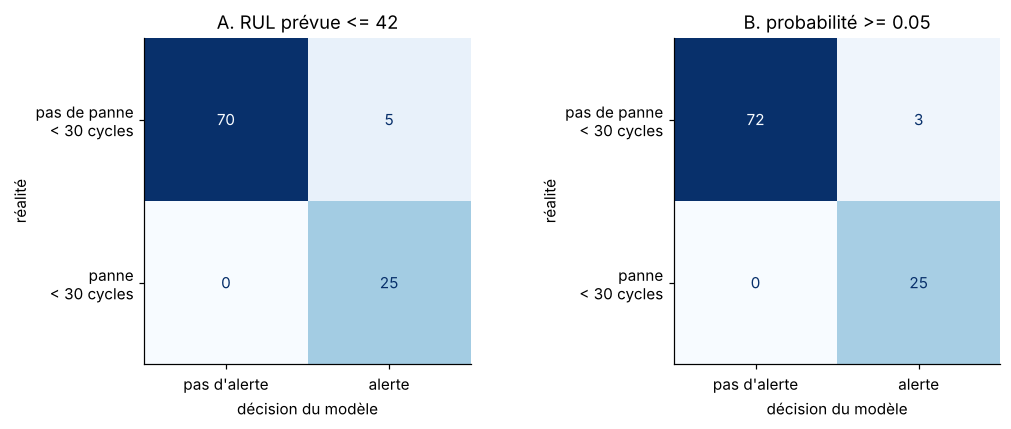

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nom, alerte) in zip(axes, [(f"A. RUL prévue <= {s_opt:.0f}", alerte_A), (f"B. probabilité >= {p_opt:.2f}", alerte_B)]):
    ConfusionMatrixDisplay(confusion_matrix(y_alerte_test, alerte, labels=[0, 1]),
                           display_labels=["pas de panne\n< 30 cycles", "panne\n< 30 cycles"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set(title=nom, xlabel="décision du modèle", ylabel="réalité"); ax.grid(False)
ax.set_xticklabels(["pas d'alerte", "alerte"]); axes[0].set_xticklabels(["pas d'alerte", "alerte"])
plt.tight_layout(); plt.savefig(FIG / "07_matrice_confusion.png", bbox_inches="tight"); plt.show()

## 8. Pourquoi le modèle prévoit-il une panne ? (valeurs de Shapley)

En aéronautique, un modèle « boîte noire » ne sera jamais certifié. On calcule les **valeurs de Shapley** (directement avec XGBoost, `pred_contribs=True`) : pour chaque prévision, la contribution de chaque variable. On les regroupe ensuite par capteur physique.

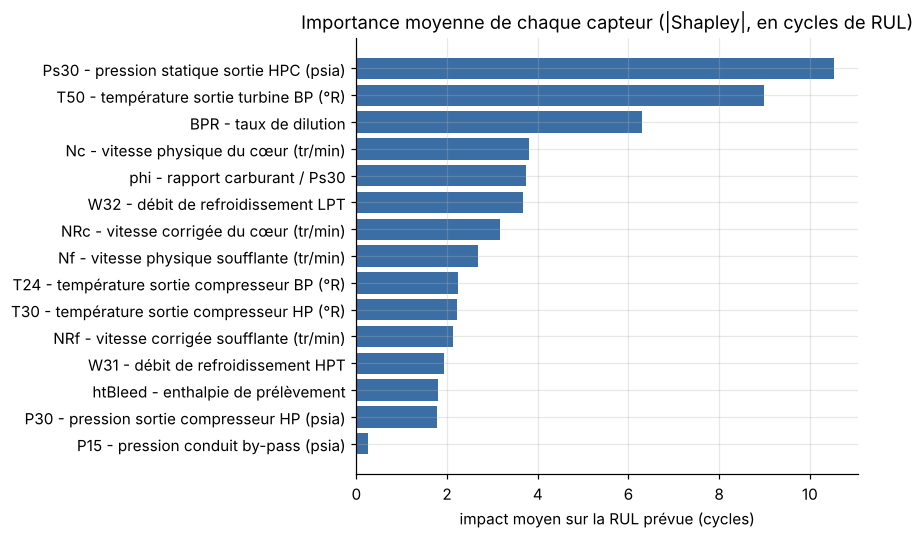

Numéro de cycle seul : 5.4 cycles d'impact moyen


In [15]:
booster = modeles["XGBoost"].get_booster()
dm = xgb.DMatrix(X_test.loc[fin_test, COLS])
contrib = booster.predict(dm, pred_contribs=True)[:, :-1]   # dernière colonne = constante
shap_df = pd.DataFrame(contrib, columns=COLS)

def capteur_de(col):
    return col.split("_")[0]

imp = shap_df.abs().mean().groupby(capteur_de).sum().drop("cycle", errors="ignore").sort_values()
imp_cycle = shap_df.abs().mean().get("cycle", 0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([D.CAPTEURS[c] for c in imp.index], imp, color="#3b6ea5")
ax.set(title="Importance moyenne de chaque capteur (|Shapley|, en cycles de RUL)", xlabel="impact moyen sur la RUL prévue (cycles)")
plt.tight_layout(); plt.savefig(FIG / "08_importance_capteurs.png", bbox_inches="tight"); plt.show()
print(f"Numéro de cycle seul : {imp_cycle:.1f} cycles d'impact moyen")

In [16]:
type_var = shap_df.abs().mean().drop("cycle", errors="ignore")
famille = type_var.groupby(lambda c: "valeur brute" if "_" not in c else
                           {"moy5": "moyenne 5 cycles", "moy20": "moyenne 20 cycles", "std20": "écart-type 20 cycles",
                            "pente20": "pente 20 cycles", "derive": "dérive vs état neuf"}[c.split("_", 1)[1]]).sum()
(famille / famille.sum()).sort_values(ascending=False).rename("part de l'importance").to_frame()

,part de l'importance
dérive vs état neuf,0.712
moyenne 20 cycles,0.137
moyenne 5 cycles,0.102
écart-type 20 cycles,0.030
pente 20 cycles,0.019
valeur brute,0.001


**Lecture** : le modèle s'appuie surtout sur les **tendances lissées** (moyennes glissantes, dérive par rapport à l'état neuf) plutôt que sur la mesure brute, qui est bruitée. Les capteurs dominants (températures en sortie de compresseur et de turbine, pression statique Ps30, vitesse du cœur) sont exactement ceux qu'affecte une usure du compresseur haute pression : le modèle a retrouvé une **physique cohérente**, ce qui renforce la confiance qu'on peut lui accorder.

## 9. Généralisation : un autre scénario (FD003, deux modes de panne)

Dans FD003, les moteurs peuvent tomber en panne de deux façons : usure du compresseur HP **ou** de la soufflante. On relance exactement le même pipeline, sans rien régler de plus. Si les performances tiennent, c'est que la méthode ne dépend pas d'un réglage fait sur mesure pour FD001.

In [17]:
tr3, te3 = D.charger("FD003")
caps3 = D.capteurs_utiles(tr3)
X3, X3_test = F.construire(tr3, caps3), F.construire(te3, caps3)
C3 = F.colonnes_X(X3)
y3 = tr3["RUL"].clip(upper=D.RUL_MAX)
fin3 = te3.groupby("moteur")["cycle"].idxmax().values
y3_test = te3.loc[fin3, "RUL"].clip(upper=D.RUL_MAX).to_numpy()

lignes = []
for nom, modele in M.modeles_regression().items():
    modele.fit(X3[C3], y3)
    lignes.append({"modèle": nom, **E.resume_regression(y3_test, np.clip(modele.predict(X3_test.loc[fin3, C3]), 0, None))})
resultats_fd003 = pd.DataFrame(lignes).set_index("modèle")
resultats_fd003.to_csv(RES / "resultats_test_fd003.csv")
resultats_fd003

,RMSE,MAE,R²,Score NASA
modèle,,,,
Ridge (linéaire),15.413,12.445,0.845,453.266
Forêt aléatoire,11.864,8.536,0.908,270.135
XGBoost,10.592,7.428,0.927,221.501


## 10. Résumé

In [18]:
r = resultats.loc["XGBoost"]; r3 = resultats_fd003.loc["XGBoost"]
dA = decisions.iloc[1]
print(f"""
RÉSUMÉ ({SOUS_JEU}, jeu de test officiel NASA, 100 moteurs)
- Meilleur modèle : {meilleur}
- XGBoost : erreur typique (RMSE) de {r['RMSE']:.1f} cycles, R² = {r['R²']:.2f}, score NASA = {r['Score NASA']:.0f}
- Gain par rapport à la régression linéaire : {(1 - r['RMSE'] / resultats.loc['Ridge (linéaire)', 'RMSE']) * 100:.0f} % d'erreur en moins
- Règle d'alerte retenue : inspection si RUL prévue <= {s_opt:.0f} cycles
  -> pannes détectées : {dA['pannes détectées']}, fausses alertes : {dA['fausses alertes']}
- Autre scénario (FD003, deux modes de panne) : RMSE = {r3['RMSE']:.1f} cycles avec le même pipeline
""")


RÉSUMÉ (FD001, jeu de test officiel NASA, 100 moteurs)
- Meilleur modèle : XGBoost
- XGBoost : erreur typique (RMSE) de 11.0 cycles, R² = 0.92, score NASA = 178
- Gain par rapport à la régression linéaire : 33 % d'erreur en moins
- Règle d'alerte retenue : inspection si RUL prévue <= 42 cycles
  -> pannes détectées : 25/25, fausses alertes : 5
- Autre scénario (FD003, deux modes de panne) : RMSE = 10.6 cycles avec le même pipeline



## Limites et pistes

- **Données simulées** : C-MAPSS vient d'un simulateur de la NASA, pas de vrais avions. Les vraies données moteur sont confidentielles (motoristes, compagnies). La méthode, elle, est celle utilisée en industrie.
- **Une seule cause** : un accident résulte en général d'une chaîne d'événements (météo, facteur humain, maintenance, conception). Ce projet traite un maillon : anticiper la défaillance moteur.
- **Conditions de vol variables** (FD002, FD004) : il faudrait normaliser chaque capteur par régime de vol (clustering des réglages) avant de construire les variables.
- **Incertitude** : donner un intervalle (régression quantile, XGBoost avec `reg:quantileerror`) plutôt qu'un seul chiffre, pour une décision encore plus prudente.
- **Deep learning** : comparer à un LSTM ou un CNN 1D sur les séquences brutes.